# 3. What drives the rating

Which topics push a review up or down, and which words do customers use for them?

### Table of contents
3.1 Setup  
3.2 Rating when a topic is mentioned  
3.3 Regression: the effect of each topic in stars  
3.4 Locals vs international shoppers  
3.5 Phrases customers use  
3.6 Save tables for Power BI

## 3.1 Setup

In [1]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_style('whitegrid')
txt = pd.read_csv('../data_private/reviews_tagged.csv')
themes = ['Warm, expert advice', 'Rude or unhelpful staff', 'Queues and crowding', 'Gifts, samples, engraving', 'Price and value',
          'Stock availability', 'Language spoken', 'Tax refund', 'Authenticity and trust']
print(len(txt), 'written reviews')

12502 written reviews


## 3.2 Rating when a topic is mentioned

A first, simple view: average stars of reviews that mention the topic vs reviews that do not.

In [2]:
simple = pd.DataFrame({t: {'mentioned': txt.loc[txt[t], 'rating'].mean(), 'not mentioned': txt.loc[~txt[t], 'rating'].mean(),
                           'reviews': int(txt[t].sum())} for t in themes}).T
simple['gap'] = simple['mentioned'] - simple['not mentioned']
simple.round(2).sort_values('gap')

,mentioned,not mentioned,reviews,gap
Rude or unhelpful staff,1.61,4.61,368.0,-3.00
Stock availability,3.19,4.54,145.0,-1.35
Authenticity and trust,3.45,4.52,38.0,-1.08
Price and value,3.55,4.56,462.0,-1.01
"Gifts, samples, engraving",3.57,4.56,490.0,-0.99
Queues and crowding,3.66,4.56,485.0,-0.89
Tax refund,3.67,4.53,94.0,-0.86
Language spoken,3.68,4.53,93.0,-0.85
"Warm, expert advice",4.84,4.37,4031.0,0.47


## 3.3 Regression: the effect of each topic in stars

A review can mention several topics, and some stores or shopper groups rate higher in general. A linear regression separates these effects:

rating = topics mentioned + store + language of the review + staff named

Each topic coefficient reads as: *mentioning this topic changes the rating by X stars, other things equal*. Reviews that thank a named staff member are kept in the model as a control.

In [3]:
def topic_effects(data):
    X = pd.get_dummies(data[themes + ['staff_named', 'store', 'language_group']], columns=['store', 'language_group'], drop_first=True).astype(float)
    model = LinearRegression().fit(X, data['rating'])
    eff = pd.Series(model.coef_, index=X.columns)[themes]
    return eff, model.score(X, data['rating'])

effects, r2 = topic_effects(txt)
print('R squared:', round(r2, 3))
effects.round(2).sort_values()

R squared: 0.319


Rude or unhelpful staff     -2.63
Stock availability          -0.91
Price and value             -0.72
Authenticity and trust      -0.68
Gifts, samples, engraving   -0.64
Queues and crowding         -0.62
Tax refund                  -0.44
Language spoken             -0.31
Warm, expert advice          0.35
dtype: float64

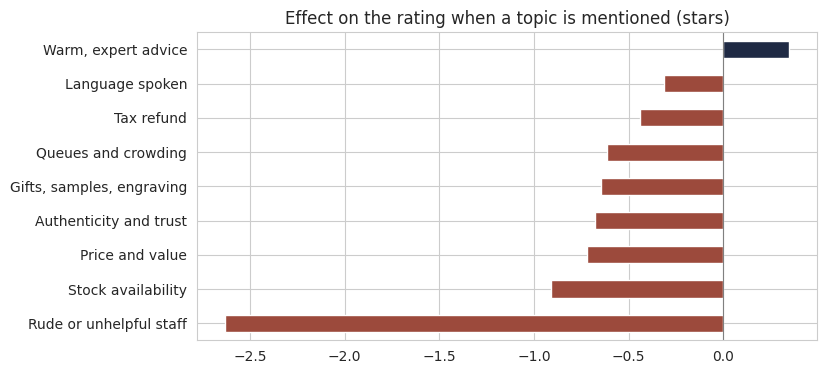

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
effects.sort_values().plot(kind='barh', ax=ax, color=['#9C4A3C' if v < 0 else '#1F2A44' for v in effects.sort_values()])
ax.set_title('Effect on the rating when a topic is mentioned (stars)')
ax.axvline(0, color='grey', lw=0.8)
plt.show()

The model explains only part of the rating (R squared above): most of what makes a review 5 stars or 1 star is not captured by keywords. The coefficients are still useful to **rank** topics by how much they move the rating.

## 3.4 Locals vs international shoppers

In [5]:
by_group = {}
for name, part in [('Local (French)', txt[txt['language_group'] == 'French']),
                   ('International (English and other)', txt[txt['language_group'] != 'French'])]:
    by_group[name] = topic_effects(part)[0]
by_group = pd.DataFrame(by_group)
by_group.round(2)

,Local (French),International (English and other)
"Warm, expert advice",0.36,0.32
Rude or unhelpful staff,-2.47,-2.86
Queues and crowding,-0.65,-0.56
"Gifts, samples, engraving",-0.83,-0.18
Price and value,-0.91,-0.55
Stock availability,-1.19,-0.30
Language spoken,-0.46,-0.29
Tax refund,-1.44,-0.26
Authenticity and trust,-0.58,-0.81


## 3.5 Phrases customers use

For each topic, the word pairs that appear most often around the topic keyword, in positive (4-5 stars) and negative (1-2 stars) reviews.  
Capitalised words in the middle of a sentence (mostly staff names) are removed first, and only pairs used at least 5 times are kept, so no single review can be identified.

In [6]:
keywords = {
    'Warm, expert advice': r'helpful|friendly|knowledgeable|attentive|welcoming|patient|advice',
    'Rude or unhelpful staff': r'rude|rudely|ignored|unhelpful|arrogant|condescending|unfriendly|unpleasant|disrespectful|judged|unwelcoming',
    'Queues and crowding': r'queues?|queuing|waiting|waited|wait|crowded|crowds?|packed|line',
    'Gifts, samples, engraving': r'gift|wrap\w*|wrapping|samples?|engrav\w*|packaging',
    'Price and value': r'prices?|pricey|expensive|cheap|cheaper|overpriced|value|discount|promotion',
    'Stock availability': r'stock|available|unavailable|find',
    'Language spoken': r'english|language|fluent|mandarin|speak|speaks|translat\w*',
    'Tax refund': r'tax|refund|detax|vat',
    'Authenticity and trust': r'fake|authentic|authenticity|counterfeit|scam|scammed|expired'}
stop = set('thank thanks a an the and or but to of in on at for with is was were are be been it this that my our we i you they he she her his them me us so very really too not just also there here have has had do did as by from all any its it\'s i\'m im'.split())

def clean_words(text):
    text = re.sub(r'(?<=[a-z,;] )[A-Z][a-zà-ÿ]+', ' ', text)
    return re.findall(r"[a-z']+", text.lower())

rows = []
for t in themes:
    kw = re.compile(rf'^(?:{keywords[t]})$')
    for tone, part in [('Positive', txt[txt[t] & (txt['rating'] >= 4)]), ('Negative', txt[txt[t] & (txt['rating'] <= 2)])]:
        if (t, tone) in [('Warm, expert advice', 'Negative'), ('Rude or unhelpful staff', 'Positive')]:
            continue
        pairs = Counter()
        for text in part['text_en']:
            w = clean_words(text)
            for i, word in enumerate(w):
                if kw.match(word):
                    if i > 0 and w[i - 1] not in stop:
                        pairs[w[i - 1] + ' ' + word] += 1
                    if i + 1 < len(w) and w[i + 1] not in stop:
                        pairs[word + ' ' + w[i + 1]] += 1
        for phrase, n in pairs.most_common(6):
            if n >= 5:
                rows.append({'theme': t, 'tone': tone, 'phrase': phrase, 'count': n})
phrases = pd.DataFrame(rows)
phrases[phrases['theme'] == 'Queues and crowding']

,theme,tone,phrase,count
12,Queues and crowding,Positive,extremely crowded,10
13,Queues and crowding,Positive,incredibly crowded,7
14,Queues and crowding,Positive,always crowded,7
15,Queues and crowding,Positive,while waiting,5
16,Queues and crowding,Positive,less crowded,5
17,Queues and crowding,Positive,large crowds,5
18,Queues and crowding,Negative,waited minutes,11
19,Queues and crowding,Negative,after waiting,6
20,Queues and crowding,Negative,still waiting,5
21,Queues and crowding,Negative,long queue,5


## 3.6 Save tables for Power BI

In [7]:
drivers = pd.DataFrame({'theme': themes, 'stars_effect': effects[themes].values,
                        'stars_effect_local': by_group.iloc[:, 0][themes].values,
                        'stars_effect_international': by_group.iloc[:, 1][themes].values,
                        'avg_when_mentioned': simple.loc[themes, 'mentioned'].values,
                        'avg_when_not_mentioned': simple.loc[themes, 'not mentioned'].values,
                        'mentions': simple.loc[themes, 'reviews'].astype(int).values}).round(3)
drivers.to_csv('../data/drivers.csv', index=False)
phrases.to_csv('../data/phrases.csv', index=False)
drivers

,theme,stars_effect,stars_effect_local,stars_effect_international,avg_when_mentioned,avg_when_not_mentioned,mentions
0,"Warm, expert advice",0.346,0.356,0.318,4.838,4.371,4031
1,Rude or unhelpful staff,-2.630,-2.469,-2.862,1.611,4.610,368
2,Queues and crowding,-0.616,-0.650,-0.563,3.664,4.556,485
3,"Gifts, samples, engraving",-0.644,-0.835,-0.181,3.573,4.560,490
4,Price and value,-0.719,-0.906,-0.548,3.552,4.559,462
5,Stock availability,-0.911,-1.188,-0.304,3.186,4.537,145
6,Language spoken,-0.315,-0.464,-0.285,3.677,4.528,93
7,Tax refund,-0.437,-1.437,-0.263,3.670,4.528,94
8,Authenticity and trust,-0.677,-0.580,-0.811,3.447,4.525,38
